# Robust Recognition of Handwritten Arabic Characters in Low-Quality Images Using Preprocessing and HOG Features

- **Course:** ARTI 403 — Image Processing

- **Team:**

  \- Joud Fayez Althagafi  
  \- Layan Altamimi  
  \- Lina Bashamakh  
  \- Maryam Abu Qurain  
  \- Renad Ghazi AlYami  
  \- Retal Alharbi

- **Dataset:** AHCD — https://github.com/mloey/Arabic-Handwritten-Characters-Dataset
- **Pipeline:** center/resize → median filter → Otsu → thinning → HOG + zoning → SVM, compared with a CNN baseline

## 0. Shared contract (everyone follows this)

| Item | Rule |
|---|---|
| Images | `N×32×32`, `uint8`, character (ink) bright on a dark background after loading |
| Labels | integers `0–27` |
| Seed | `42` everywhere |
| Splits | Train / Validation / Test. Validation is carved out of the original train set (stratified). **Test is never used for tuning.** |
| Preprocessing | `preprocess(img, flags)` with flags `use_center, use_median, use_otsu, use_thin`; fixed order: center/resize → median → Otsu → thinning |
| One config = one experiment | the same config is applied to train **and** test, features are re-extracted, the scaler is re-fitted on train only, and the model is **retrained** |
| Fixed settings | HOG settings, `C` and `gamma` are chosen once on the full pipeline and stay fixed across the ablation configs |
| Degraded test sets | generated from the **raw** test set and saved as `.npy` |
| Results | every result goes through `save_result()` into `results.csv` |

`results.csv` columns: `experiment_id, model, preprocessing, hog_settings, condition, split, accuracy, precision, recall, f1`

## Download the dataset (Colab)

Downloads the four AHCD csv files into `data/` from the official repository. It is skipped automatically if `data/` already has the csv files.

In [ ]:
import os, glob
if not glob.glob("data/**/*.csv", recursive=True):
    !git clone -q --depth 1 https://github.com/mloey/Arabic-Handwritten-Characters-Dataset.git ahcd
    !mkdir -p data && unzip -q -o "ahcd/Arabic Handwritten Characters Dataset CSV.zip" -d data

## 1. Setup and shared constants

In [ ]:
import os
import glob
import json
import random
import hashlib
import tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import feature, filters, morphology, transform
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

# ---- shared constants: do NOT change without telling the whole team ----
SEED = 42
IMG_SIZE = 32
N_CLASSES = 28
VAL_FRACTION = 0.15            # share of the original train set used as validation

# ---- switches ----
DATA_DIR = "data"              # folder that holds the four AHCD csv files (searched recursively)
USE_SYNTHETIC = False          # True = fake data to smoke-test the code (separate output files; never use for the paper)
RUN_CNN = True                 # Renad: CNN implemented (needs a GPU runtime on Colab)
FINAL_RUN = True               # Lina: final "Run All"

# ---- output locations ----
_SUFFIX = "_SYNTHETIC" if USE_SYNTHETIC else ""
RESULTS_PATH = f"results{_SUFFIX}.csv"
DEGRADED_DIR = f"degraded_sets{_SUFFIX}"
FIG_DIR = f"figures{_SUFFIX}"

# ---- results.csv schema ----
RESULT_COLUMNS = ["experiment_id", "model", "preprocessing", "hog_settings",
                  "condition", "split", "accuracy", "precision", "recall", "f1"]
KEY_COLUMNS = ["experiment_id", "model", "preprocessing", "hog_settings", "condition", "split"]
METRIC_COLUMNS = ["accuracy", "precision", "recall", "f1"]
NO_HOG = "no_hog"              # value of the hog_settings column for models that do not use HOG (CNN)


def set_seed(seed=SEED):
    """Fix the python and numpy random generators (Renad also fixes her deep-learning framework)."""
    random.seed(seed)
    np.random.seed(seed)


set_seed()


def show(obj):
    """Display a DataFrame / figure in Jupyter or Colab, print it anywhere else."""
    try:
        display(obj)
    except NameError:
        print(obj)

### Status board
Every owner flips her own entries to `True` (inside her own section) when her part is final.

In [ ]:
IMPLEMENTED = {
    "loader (Layan)": False,
    "center_resize (Layan)": False,
    "median (Maryam)": False,
    "degraded_sets (Maryam)": False,
    "evaluation (Maryam)": False,
    "otsu (Lina)": False,
    "thinning (Lina)": False,
    "preprocess_and_configs (Lina)": False,
    "features_hog_zoning (Joud)": False,
    "svm (Retal)": False,
    "cnn (Renad)": False,
}


def readiness_report():
    """Print which parts are still marked as not final. Returns True only when everything is final."""
    for name, done in IMPLEMENTED.items():
        print(f"[{'x' if done else ' '}] {name}")
    return all(IMPLEMENTED.values())

### Contract checks (used everywhere)

In [ ]:
def assert_images(X, name="X"):
    """Contract: N x 32 x 32, uint8."""
    assert isinstance(X, np.ndarray), f"{name}: expected a numpy array, got {type(X)}"
    assert X.ndim == 3 and X.shape[1:] == (IMG_SIZE, IMG_SIZE), \
        f"{name}: expected shape (N, {IMG_SIZE}, {IMG_SIZE}), got {X.shape}"
    assert X.dtype == np.uint8, f"{name}: expected dtype uint8, got {X.dtype}"


def assert_labels(y, n=None, name="y"):
    """Contract: 1-D integer array with values 0..27 (and length n if given)."""
    assert isinstance(y, np.ndarray) and y.ndim == 1, f"{name}: expected a 1-D numpy array"
    assert np.issubdtype(y.dtype, np.integer), f"{name}: expected integer labels, got {y.dtype}"
    assert y.min() >= 0 and y.max() <= N_CLASSES - 1, \
        f"{name}: labels must be in 0..{N_CLASSES - 1}, got {y.min()}..{y.max()}"
    if n is not None:
        assert len(y) == n, f"{name}: expected {n} labels, got {len(y)}"

## 2. Data (owner: Layan)

Done (Layan):
- load AHCD from the four csv files and shift the labels from `1–28` to `0–27`;
- orientation and ink polarity verified against the official AHCD png images (`TRANSPOSE_IMAGES = True`, `INVERT_IMAGES = False`);
- the one fully blank image in the train csv is removed before the split (`DROP_BLANK_TRAIN`);
- stratified validation split (15%) from the original train set; the test set is never touched;
- EDA: sample grid, class distribution and a summary table (figures saved in `figures/`).

In [ ]:
TRANSPOSE_IMAGES = True        # verified (Layan): the csv rows are stored transposed; checked against the official AHCD png images
INVERT_IMAGES = False          # verified (Layan): AHCD is already white ink on a black background
DROP_BLANK_TRAIN = True        # AHCD has one fully blank image in the train csv; it is removed BEFORE the split (the test set is never touched)


def make_synthetic_data(n_train_per_class=40, n_test_per_class=12, seed=SEED):
    """Fake 'letters' (a few random strokes per class) so the code can be smoke-tested without AHCD."""
    from skimage.draw import line
    templates = []
    for c in range(N_CLASSES):
        trng = np.random.RandomState(1000 + c)
        templates.append([trng.randint(8, 24, size=4) for _ in range(3)])
    rng = np.random.RandomState(seed)

    def draw(c):
        img = np.zeros((IMG_SIZE, IMG_SIZE), dtype=bool)
        dr, dc = rng.randint(-3, 4, size=2)
        for r0, c0, r1, c1 in templates[c]:
            rr, cc = line(int(r0) + dr, int(c0) + dc, int(r1) + dr, int(c1) + dc)
            ok = (rr >= 0) & (rr < IMG_SIZE) & (cc >= 0) & (cc < IMG_SIZE)
            img[rr[ok], cc[ok]] = True
        img = ndi.binary_dilation(img, iterations=1)
        return img.astype(np.uint8) * 255

    def build(n_per_class):
        X = np.stack([draw(c) for c in range(N_CLASSES) for _ in range(n_per_class)])
        y = np.repeat(np.arange(N_CLASSES), n_per_class).astype(np.int64)
        return X, y

    X_train_all, y_train_all = build(n_train_per_class)
    X_test, y_test = build(n_test_per_class)
    return X_train_all, y_train_all, X_test, y_test


def _find_csv(data_dir, keyword):
    """Find exactly one csv under data_dir whose file name contains `keyword` (case-insensitive)."""
    all_csv = sorted(glob.glob(os.path.join(data_dir, "**", "*.csv"), recursive=True))
    hits = [p for p in all_csv if keyword in os.path.basename(p).lower()]
    if len(hits) != 1:
        raise FileNotFoundError(
            f"Expected exactly one csv whose name contains '{keyword}' under '{data_dir}', found {len(hits)}. "
            f"csv files found: {all_csv}. Put the four AHCD csv files in '{data_dir}' or change DATA_DIR.")
    return hits[0]


def _read_images_csv(path):
    arr = pd.read_csv(path, header=None).to_numpy()
    if arr.shape[1] != IMG_SIZE * IMG_SIZE:
        raise ValueError(f"{path}: expected {IMG_SIZE * IMG_SIZE} columns per row, got {arr.shape[1]}")
    if arr.min() < 0 or arr.max() > 255:
        raise ValueError(f"{path}: pixel values must be in 0..255, got {arr.min()}..{arr.max()}")
    X = arr.astype(np.uint8).reshape(-1, IMG_SIZE, IMG_SIZE)
    if TRANSPOSE_IMAGES:
        X = X.transpose(0, 2, 1)
    if INVERT_IMAGES:
        X = (255 - X.astype(np.int16)).astype(np.uint8)
    return np.ascontiguousarray(X)


def _read_labels_csv(path):
    y = pd.read_csv(path, header=None).to_numpy().ravel().astype(np.int64)
    if y.max() == N_CLASSES:                       # AHCD labels are 1..28 -> shift to 0..27
        if y.min() < 1:
            raise ValueError(f"{path}: labels look 1-based (max = {N_CLASSES}) but contain {y.min()}")
        y = y - 1
    return y


def split_train_val(X, y, val_fraction=VAL_FRACTION, seed=SEED):
    """Stratified split of the original train set into train / validation."""
    idx = np.arange(len(y))
    tr, va = train_test_split(idx, test_size=val_fraction, stratify=y, random_state=seed)
    return X[tr], y[tr], X[va], y[va]


def load_ahcd(data_dir=DATA_DIR):
    """Return X_train, y_train, X_val, y_val, X_test, y_test (all checked against the shared contract)."""
    if USE_SYNTHETIC:
        X_all, y_all, X_te, y_te = make_synthetic_data()
    else:
        X_all = _read_images_csv(_find_csv(data_dir, "trainimages"))
        y_all = _read_labels_csv(_find_csv(data_dir, "trainlabel"))
        X_te = _read_images_csv(_find_csv(data_dir, "testimages"))
        y_te = _read_labels_csv(_find_csv(data_dir, "testlabel"))
    assert_images(X_all, "X_train_all")
    assert_labels(y_all, len(X_all), "y_train_all")
    assert_images(X_te, "X_test")
    assert_labels(y_te, len(X_te), "y_test")
    if DROP_BLANK_TRAIN:
        blank = X_all.max(axis=(1, 2)) == X_all.min(axis=(1, 2))
        if blank.any():
            print(f"removed {int(blank.sum())} blank train image(s), labels {y_all[blank].tolist()}")
            X_all, y_all = X_all[~blank], y_all[~blank]
    X_tr, y_tr, X_va, y_va = split_train_val(X_all, y_all)
    return X_tr, y_tr, X_va, y_va, X_te, y_te


X_train, y_train, X_val, y_val, X_test, y_test = load_ahcd()
print("train", X_train.shape, "| val", X_val.shape, "| test", X_test.shape)
IMPLEMENTED["loader (Layan)"] = True

removed 1 blank train image(s), labels [0]
train (11423, 32, 32) | val (2016, 32, 32) | test (3360, 32, 32)


### EDA (owner: Layan)

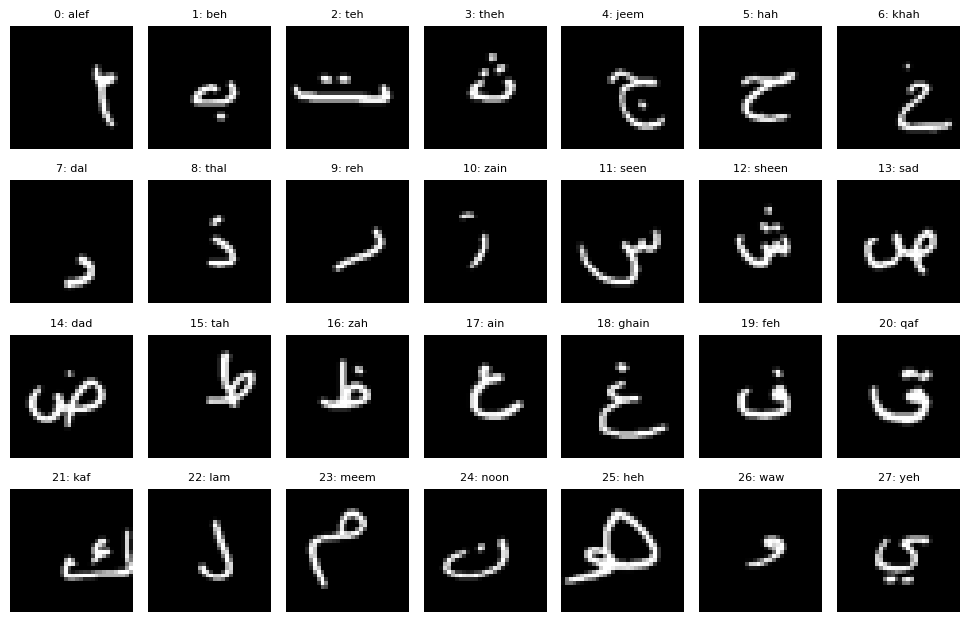

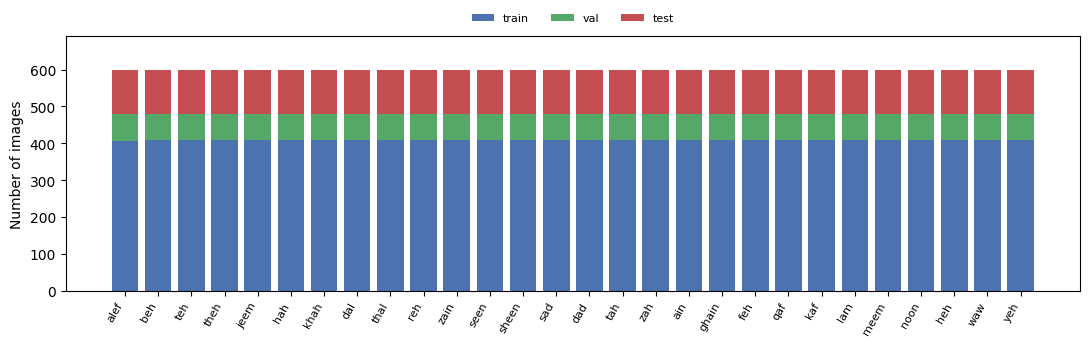

,split,images,per_class_min,per_class_max,mean_pixel,ink_ratio
0,train,11423,407,408,13.46,0.052
1,val,2016,72,72,13.63,0.052
2,test,3360,120,120,13.57,0.052


In [ ]:
# AHCD label order (0-27) follows the Arabic alphabet; checked on the sample grid
CLASS_NAMES = ["alef", "beh", "teh", "theh", "jeem", "hah", "khah", "dal", "thal", "reh",
               "zain", "seen", "sheen", "sad", "dad", "tah", "zah", "ain", "ghain", "feh",
               "qaf", "kaf", "lam", "meem", "noon", "heh", "waw", "yeh"]


def _save_fig(fig, filename):
    """Save a figure for the paper into FIG_DIR."""
    if filename:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, filename), dpi=200, bbox_inches="tight")


def show_sample_grid(X, y, cols=7, filename="fig_sample_grid.png"):
    """First sample of every class: use it to check orientation and ink polarity."""
    rows = int(np.ceil(N_CLASSES / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.4, rows * 1.6))
    for c, ax in enumerate(axes.ravel()):
        ax.axis("off")
        idx = np.where(y == c)[0] if c < N_CLASSES else []
        if len(idx):
            ax.imshow(X[idx[0]], cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"{c}: {CLASS_NAMES[c]}", fontsize=8)
    plt.tight_layout()
    _save_fig(fig, filename)
    plt.show()


def class_counts_table():
    """Number of images per class in each split."""
    return pd.DataFrame({
        "class": CLASS_NAMES,
        "train": np.bincount(y_train, minlength=N_CLASSES),
        "val": np.bincount(y_val, minlength=N_CLASSES),
        "test": np.bincount(y_test, minlength=N_CLASSES),
    })


def plot_class_distribution(filename="fig_class_distribution.png"):
    """Stacked bar chart of the number of images per class (train / val / test)."""
    t = class_counts_table()
    x = np.arange(N_CLASSES)
    fig, ax = plt.subplots(figsize=(11, 3.6))
    bottom = np.zeros(N_CLASSES)
    for split, color in [("train", "#4C72B0"), ("val", "#55A868"), ("test", "#C44E52")]:
        ax.bar(x, t[split], bottom=bottom, color=color, label=split, width=0.8)
        bottom += t[split].to_numpy()
    ax.set_xticks(x)
    ax.set_xticklabels(CLASS_NAMES, rotation=60, ha="right", fontsize=8)
    ax.set_ylabel("Number of images")
    ax.set_ylim(0, bottom.max() * 1.15)
    ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.13), frameon=False)
    plt.tight_layout()
    _save_fig(fig, filename)
    plt.show()


def dataset_summary():
    """One-row-per-split summary for the Dataset section of the paper."""
    rows = []
    for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
        counts = np.bincount(y, minlength=N_CLASSES)
        rows.append({"split": name, "images": len(X), "per_class_min": counts.min(), "per_class_max": counts.max(),
                     "mean_pixel": round(float(X.mean()), 2), "ink_ratio": round(float((X > 127).mean()), 3)})
    return pd.DataFrame(rows)


show_sample_grid(X_train, y_train)
plot_class_distribution()
show(dataset_summary())

## 3. Preprocessing steps

One function per step, all with the same contract: `uint8 32×32` in, `uint8 32×32` out.
The versions below are first working versions; each owner reviews hers and sets her `IMPLEMENTED` entry to `True`.

### 3.1 Centering and resizing (owner: Layan)

Done (Layan): the character's bounding box is found with Otsu, padded to a square with the background value (keeps the aspect ratio), given a 2-pixel margin and resized to 32×32. The cell also saves the before/after figure and prints how much of the frame the character covers before and after.

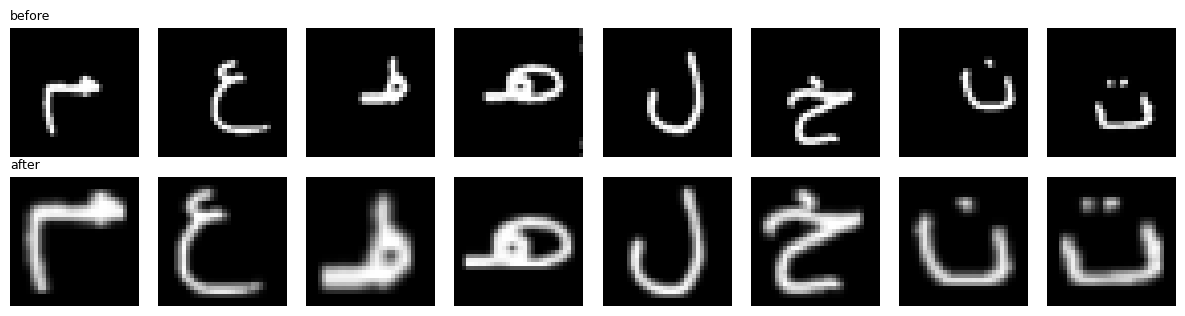

bounding box share of the frame (before, after): (0.202, 0.464)


In [ ]:
def _background_level(img):
    """Median of the border pixels: a robust estimate of the background grey level."""
    border = np.concatenate([img[0, :], img[-1, :], img[:, 0], img[:, -1]])
    return int(np.median(border))


def center_resize(img, out_size=IMG_SIZE, margin=2):
    """Crop the character's bounding box, pad it to a square (keeps the aspect ratio), resize to out_size x out_size."""
    img = np.asarray(img, dtype=np.uint8)
    if img.max() == img.min():                       # blank image: nothing to center
        return img.copy()
    bg = _background_level(img)
    t = filters.threshold_otsu(img)
    ink = (img <= t) if bg > t else (img > t)        # ink = the side of the threshold opposite to the background
    rows, cols = np.where(ink)
    if rows.size == 0:
        return img.copy()
    crop = img[rows.min():rows.max() + 1, cols.min():cols.max() + 1]
    h, w = crop.shape
    side = max(h, w)
    pad_h, pad_w = side - h, side - w
    crop = np.pad(crop, ((pad_h // 2, pad_h - pad_h // 2), (pad_w // 2, pad_w - pad_w // 2)),
                  mode="constant", constant_values=bg)
    crop = np.pad(crop, margin, mode="constant", constant_values=bg)
    out = transform.resize(crop, (out_size, out_size), order=1, anti_aliasing=True, preserve_range=True)
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


def show_center_resize_examples(X, n=8, seed=SEED, filename="fig_center_resize.png"):
    """Before/after figure for the paper: raw images (top) and after center_resize (bottom)."""
    idx = np.random.RandomState(seed).choice(len(X), n, replace=False)
    fig, axes = plt.subplots(2, n, figsize=(1.5 * n, 3.2))
    for j, i in enumerate(idx):
        axes[0, j].imshow(X[i], cmap="gray", vmin=0, vmax=255)
        axes[1, j].imshow(center_resize(X[i]), cmap="gray", vmin=0, vmax=255)
        axes[0, j].axis("off")
        axes[1, j].axis("off")
    axes[0, 0].set_title("before", fontsize=9, loc="left")
    axes[1, 0].set_title("after", fontsize=9, loc="left")
    plt.tight_layout()
    _save_fig(fig, filename)
    plt.show()


def ink_bbox_fraction(X):
    """Mean share of the 32x32 frame covered by the character's bounding box (before vs after centering)."""
    def frac(img):
        t = filters.threshold_otsu(img)
        r, c = np.where(img > t)
        return (r.max() - r.min() + 1) * (c.max() - c.min() + 1) / IMG_SIZE ** 2
    before = np.mean([frac(x) for x in X])
    after = np.mean([frac(center_resize(x)) for x in X])
    return round(float(before), 3), round(float(after), 3)


show_center_resize_examples(X_train)
print("bounding box share of the frame (before, after):", ink_bbox_fraction(X_train[:1000]))
IMPLEMENTED["center_resize (Layan)"] = True

### 3.2 Median filter (owner: Maryam)

Done (Maryam): 3×3 median filter with a **cross-shaped** (plus) kernel, applied after center/resize.
Kernel choice (checked on the AHCD validation set): inside the pipeline, a 3×3 **square** median erased at least one dot
in about 18% of the dotted letters, the 3×3 **cross** kernel in about 11%, and a 5×5 square in about 55%.
The before/after figure (`fig_median_before_after.png`) is made right after section 4, because it uses the noisy test set.

In [ ]:
MEDIAN_SHAPE = "cross"    # "cross" (plus-shaped 3x3) keeps the small dots of Arabic letters better than "square"


def median_denoise(img, size=3, shape=None):
    """Median filter. shape='cross' uses a plus-shaped size x size kernel, shape='square' a full size x size kernel."""
    img = np.asarray(img, dtype=np.uint8)
    shape = shape or MEDIAN_SHAPE
    if shape == "square":
        return ndi.median_filter(img, size=size, mode="nearest")
    if shape == "cross":
        footprint = np.zeros((size, size), dtype=bool)
        footprint[size // 2, :] = True
        footprint[:, size // 2] = True
        return ndi.median_filter(img, footprint=footprint, mode="nearest")
    raise ValueError(f"MEDIAN_SHAPE must be 'cross' or 'square', got {shape!r}")


IMPLEMENTED["median (Maryam)"] = True

### 3.3 Otsu thresholding and thinning (owner: Lina)

Done (Lina):
- `otsu_binarize()` gives a binary image with ink = 255 whatever the original polarity; `thin_image()` skeletonizes it;
- dots are kept: on 1000 training images thinning changed the number of connected components in 0.0% of images (dot check below);
- without Otsu (`abl_no_otsu`), `thin_image()` binarizes with a fixed threshold of 127; the comparison after section 4 shows this blanks 36.6% of the `blur_5` images, against 0% with Otsu;
- figures: `otsu_thinning_dots.png` (dotted classes before/after) and the step-by-step figure in 3.4.

In [ ]:
def otsu_binarize(img):
    """Otsu threshold -> binary image with ink = 255 and background = 0 (whatever the original polarity was)."""
    img = np.asarray(img, dtype=np.uint8)
    if img.max() == img.min():                       # blank image: Otsu is undefined
        return np.zeros_like(img)
    t = filters.threshold_otsu(img)
    ink = (img <= t) if _background_level(img) > t else (img > t)
    return ink.astype(np.uint8) * 255


def thin_image(img):
    """Skeletonize the ink (expects ink bright). A non-binary input is binarized with a fixed threshold of 127."""
    img = np.asarray(img, dtype=np.uint8)
    skeleton = morphology.thin(img > 127)
    return skeleton.astype(np.uint8) * 255


def count_components(img):
    """Number of 8-connected ink components (use it to check that thinning keeps the dots)."""
    _, n = ndi.label(np.asarray(img) > 127, structure=np.ones((3, 3), dtype=int))
    return n


IMPLEMENTED["otsu (Lina)"] = True
IMPLEMENTED["thinning (Lina)"] = True

### 3.4 The preprocessing pipeline and the ablation configs (owner: Lina)

Done (Lina): `preprocess(img, flags)` applies the enabled steps in the fixed order center/resize → median → Otsu → thinning.
The six config names below are final and are the `experiment_id` values of the ablation: `main_full`, `abl_no_center`, `abl_no_median`, `abl_no_otsu`, `abl_no_thin`, `abl_none`.

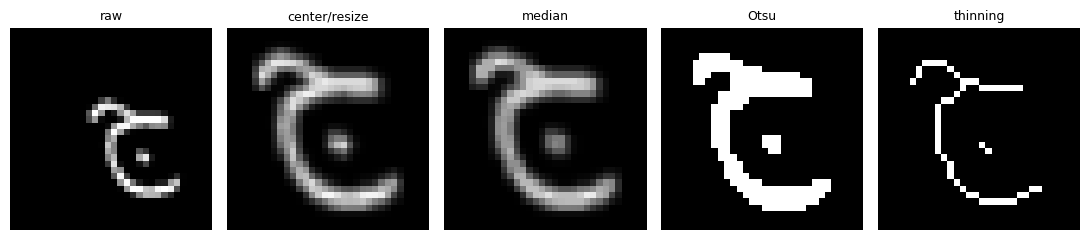

In [ ]:
FLAG_NAMES = ("use_center", "use_median", "use_otsu", "use_thin")

CONFIGS = {
    "main_full":     dict(use_center=True,  use_median=True,  use_otsu=True,  use_thin=True),
    "abl_no_center": dict(use_center=False, use_median=True,  use_otsu=True,  use_thin=True),
    "abl_no_median": dict(use_center=True,  use_median=False, use_otsu=True,  use_thin=True),
    "abl_no_otsu":   dict(use_center=True,  use_median=True,  use_otsu=False, use_thin=True),
    "abl_no_thin":   dict(use_center=True,  use_median=True,  use_otsu=True,  use_thin=False),
    "abl_none":      dict(use_center=False, use_median=False, use_otsu=False, use_thin=False),
}


def _check_flags(flags):
    missing = [f for f in FLAG_NAMES if f not in flags]
    unknown = [f for f in flags if f not in FLAG_NAMES]
    if missing or unknown:
        raise KeyError(f"flags must be exactly {FLAG_NAMES}; missing={missing}, unknown={unknown}")


def flags_to_string(flags):
    """Readable name for the `preprocessing` column, e.g. 'center+median+otsu+thin' or 'raw'."""
    _check_flags(flags)
    names = [f.replace("use_", "") for f in FLAG_NAMES if flags[f]]
    return "+".join(names) if names else "raw"


def preprocess(img, flags):
    """Apply the enabled steps to ONE image in the fixed order: center/resize -> median -> Otsu -> thinning."""
    _check_flags(flags)
    out = np.asarray(img, dtype=np.uint8)
    if flags["use_center"]:
        out = center_resize(out)
    if flags["use_median"]:
        out = median_denoise(out)
    if flags["use_otsu"]:
        out = otsu_binarize(out)
    if flags["use_thin"]:
        out = thin_image(out)
    return out


def preprocess_batch(X, flags):
    """Apply preprocess() to every image. Input and output follow the shared contract (N x 32 x 32 uint8)."""
    assert_images(X, "preprocess_batch input")
    out = np.stack([preprocess(img, flags) for img in X]).astype(np.uint8)
    assert_images(out, "preprocess_batch output")
    return out


def show_preprocessing_steps(img):
    """Before/after figure: the raw image followed by the result after each step."""
    steps = [("raw", np.asarray(img, dtype=np.uint8))]
    for name, fn in [("center/resize", center_resize), ("median", median_denoise),
                     ("Otsu", otsu_binarize), ("thinning", thin_image)]:
        steps.append((name, fn(steps[-1][1])))
    fig, axes = plt.subplots(1, len(steps), figsize=(2.2 * len(steps), 2.4))
    for ax, (name, im) in zip(axes, steps):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(name, fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


show_preprocessing_steps(X_train[0])
IMPLEMENTED["preprocess_and_configs (Lina)"] = True

In [ ]:
# Dot check (Lina): count ink pieces after each step to confirm thinning keeps the dots
def dot_check(X, y, n=1000, seed=SEED):
    """Count ink pieces (letter body + dots) after each step, on n random images."""
    rng = np.random.RandomState(seed)
    idx = rng.choice(len(X), size=min(n, len(X)), replace=False)
    rows = []
    for i in idx:
        c = center_resize(X[i])
        before_median = otsu_binarize(c)            # same path, but median skipped
        before_thin = otsu_binarize(median_denoise(c))
        after_thin = thin_image(before_thin)
        rows.append({"label": int(y[i]),
                     "no_median": count_components(before_median),
                     "before_thin": count_components(before_thin),
                     "after_thin": count_components(after_thin)})
    return pd.DataFrame(rows)


dots = dot_check(X_train, y_train)
n = len(dots)
print(f"images checked: {n}")
print(f"thinning changed the piece count in {100 * (dots.after_thin != dots.before_thin).mean():.1f}% of images")
print(f"median changed the piece count in   {100 * (dots.before_thin != dots.no_median).mean():.1f}% of images "
      f"(fewer pieces in {100 * (dots.before_thin < dots.no_median).mean():.1f}%)")
show(dots.groupby("label")[["no_median", "before_thin", "after_thin"]].mean().round(2))

images checked: 1000
thinning changed the piece count in 0.0% of images
median changed the piece count in   3.4% of images (fewer pieces in 3.3%)


,no_median,before_thin,after_thin
label,,,
0,1.60,1.60,1.60
1,1.92,1.84,1.84
2,2.64,2.59,2.59
3,3.44,3.26,3.26
4,1.87,1.83,1.83
5,1.03,1.03,1.03
6,1.97,1.87,1.87
7,1.02,1.02,1.02
8,1.92,1.88,1.88


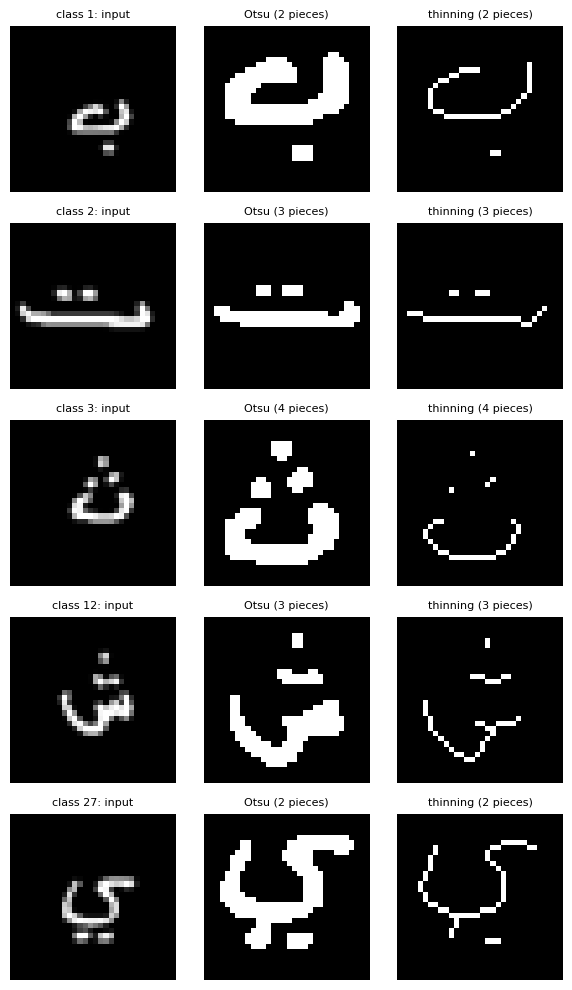

In [ ]:
DOTTED_CLASSES = [1, 2, 3, 12, 27]

def show_dot_figure(X, y, classes=DOTTED_CLASSES, filename="otsu_thinning_dots.png"):
    fig, axes = plt.subplots(len(classes), 3, figsize=(6, 2 * len(classes)))
    for row, c in zip(axes, classes):
        img = X[np.where(y == c)[0][0]]
        o = otsu_binarize(median_denoise(center_resize(img)))
        t = thin_image(o)
        for ax, (name, im) in zip(row, [("input", img), ("Otsu", o), ("thinning", t)]):
            ax.imshow(im, cmap="gray", vmin=0, vmax=255)
            title = f"class {c}: {name}" if name == "input" else f"{name} ({count_components(im)} pieces)"
            ax.set_title(title, fontsize=8)
            ax.axis("off")
    plt.tight_layout()
    os.makedirs(FIG_DIR, exist_ok=True)
    fig.savefig(os.path.join(FIG_DIR, filename), dpi=150, bbox_inches="tight")
    plt.show()


show_dot_figure(X_train, y_train)

## 4. Low-quality test sets (owner: Maryam)

Done (Maryam): six degraded copies of the test set: Gaussian noise (σ = 0.05 and 0.1 on the `[0,1]` scale), mean blur (3×3 and 5×5) and random rotation (uniform in ±5° and ±10°).
The sets are generated **from the raw test set only**, saved as `.npy`, and regenerated automatically if the test set changes.
The figures `fig_degraded_sets.png` and `fig_median_before_after.png` are made in the next cell and saved in `figures/`.

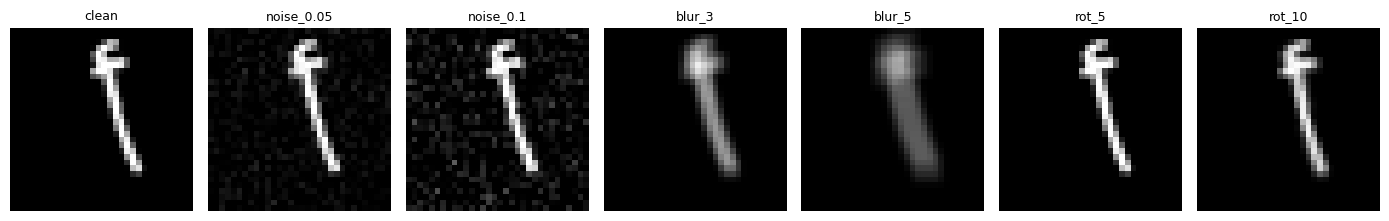

In [ ]:
DEGRADATIONS = {
    "noise_0.05": ("noise", 0.05),
    "noise_0.1":  ("noise", 0.1),
    "blur_3":     ("blur", 3),
    "blur_5":     ("blur", 5),
    "rot_5":      ("rotation", 5),
    "rot_10":     ("rotation", 10),
}
CONDITIONS = ["clean"] + list(DEGRADATIONS)


def add_gaussian_noise(X, sigma, rng):
    Xf = X.astype(np.float32) / 255.0
    noisy = Xf + rng.normal(0.0, sigma, size=Xf.shape).astype(np.float32)
    return np.rint(np.clip(noisy, 0.0, 1.0) * 255.0).astype(np.uint8)


def add_mean_blur(X, k):
    blurred = ndi.uniform_filter(X.astype(np.float32), size=(1, k, k), mode="nearest")
    return np.clip(np.rint(blurred), 0, 255).astype(np.uint8)


def add_random_rotation(X, max_angle, rng):
    out = np.empty_like(X)
    for i, img in enumerate(X):
        angle = rng.uniform(-max_angle, max_angle)
        rotated = ndi.rotate(img.astype(np.float32), angle, reshape=False, order=1,
                             mode="constant", cval=float(_background_level(img)))
        out[i] = np.clip(np.rint(rotated), 0, 255).astype(np.uint8)
    return out


def degrade(X, kind, param, seed):
    rng = np.random.RandomState(seed)
    if kind == "noise":
        return add_gaussian_noise(X, param, rng)
    if kind == "blur":
        return add_mean_blur(X, param)
    if kind == "rotation":
        return add_random_rotation(X, param, rng)
    raise ValueError(f"unknown degradation kind: {kind}")


def _degraded_meta(X_test):
    return {
        "x_test_sha1": hashlib.sha1(np.ascontiguousarray(X_test).tobytes()).hexdigest(),
        "seed": SEED,
        "degradations": {k: [v[0], v[1]] for k, v in DEGRADATIONS.items()},
    }


def load_or_generate_degraded_sets(X_test, regenerate=False):
    """Return {condition: array}. Reuses the saved .npy files only if they were made from this exact X_test."""
    assert_images(X_test, "X_test")
    meta_path = os.path.join(DEGRADED_DIR, "meta.json")
    paths = {c: os.path.join(DEGRADED_DIR, f"test_{c}.npy") for c in DEGRADATIONS}
    meta = _degraded_meta(X_test)
    up_to_date = False
    if not regenerate and os.path.exists(meta_path) and all(os.path.exists(p) for p in paths.values()):
        with open(meta_path) as f:
            up_to_date = json.load(f) == meta
    if up_to_date:
        sets = {c: np.load(p) for c, p in paths.items()}
    else:
        os.makedirs(DEGRADED_DIR, exist_ok=True)
        sets = {}
        for i, (cond, (kind, param)) in enumerate(DEGRADATIONS.items()):
            sets[cond] = degrade(X_test, kind, param, seed=SEED + 100 + i)
            np.save(paths[cond], sets[cond])
        with open(meta_path, "w") as f:
            json.dump(meta, f)
    for cond, arr in sets.items():
        assert_images(arr, f"degraded set {cond}")
        assert arr.shape == X_test.shape, f"degraded set {cond}: shape {arr.shape} != {X_test.shape}"
    return sets


def show_degraded_examples(X_test, sets, idx=0):
    """Figure for the paper: the same test image under every condition."""
    items = [("clean", X_test[idx])] + [(c, sets[c][idx]) for c in DEGRADATIONS]
    fig, axes = plt.subplots(1, len(items), figsize=(2.0 * len(items), 2.3))
    for ax, (name, im) in zip(axes, items):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(name, fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


DEGRADED = load_or_generate_degraded_sets(X_test)
show_degraded_examples(X_test, DEGRADED)
IMPLEMENTED["degraded_sets (Maryam)"] = True

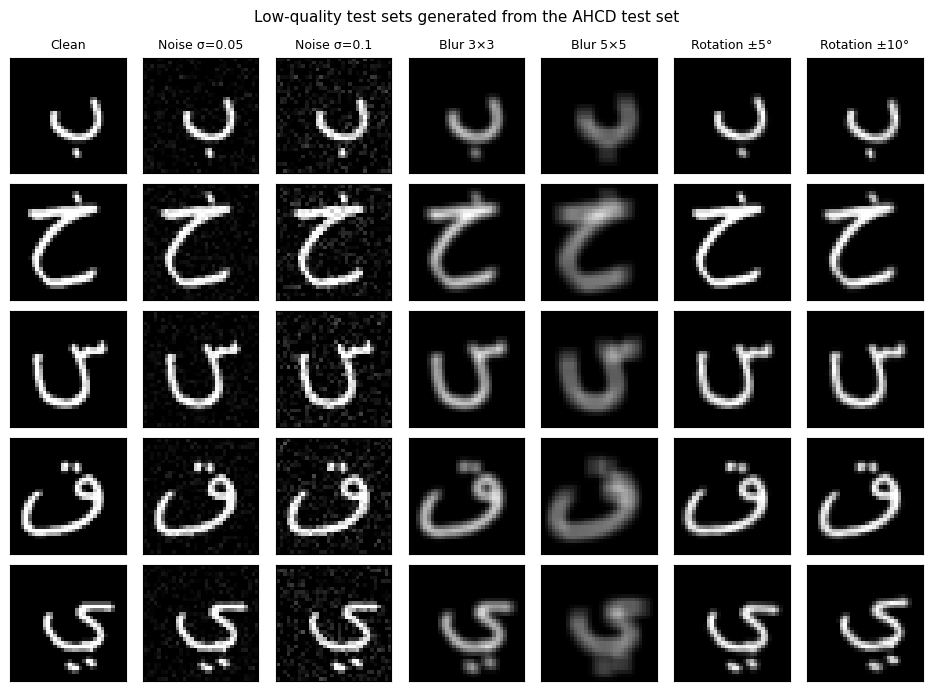

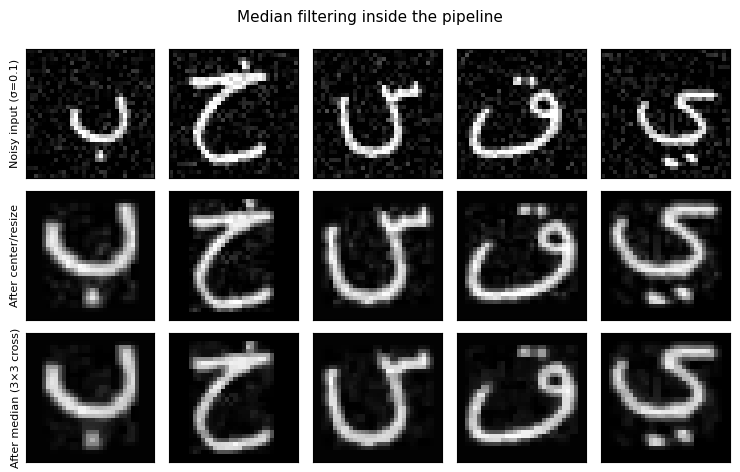

In [ ]:
# Figures for the paper (Maryam): clean vs degraded test images, and the median filter inside the pipeline.
# Both are saved in FIG_DIR, so they are included in the downloaded zip.
FIG_CLASSES = [1, 6, 11, 20, 27]                                   # beh, khah, seen, qaf, yeh
_fig_idx = [int(np.where(y_test == c)[0][3]) for c in FIG_CLASSES]
_titles = {"clean": "Clean", "noise_0.05": "Noise σ=0.05", "noise_0.1": "Noise σ=0.1", "blur_3": "Blur 3×3",
           "blur_5": "Blur 5×5", "rot_5": "Rotation ±5°", "rot_10": "Rotation ±10°"}

fig, axes = plt.subplots(len(_fig_idx), len(CONDITIONS), figsize=(len(CONDITIONS) * 1.35, len(_fig_idx) * 1.4))
for r, i in enumerate(_fig_idx):
    for c, cond in enumerate(CONDITIONS):
        im = X_test[i] if cond == "clean" else DEGRADED[cond][i]
        axes[r, c].imshow(im, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(_titles[cond], fontsize=9)
fig.suptitle("Low-quality test sets generated from the AHCD test set", fontsize=11)
plt.tight_layout()
_save_fig(fig, "fig_degraded_sets.png")
plt.show()

_rows = [("Noisy input (σ=0.1)", lambda i: DEGRADED["noise_0.1"][i]),
         ("After center/resize", lambda i: center_resize(DEGRADED["noise_0.1"][i])),
         ("After median (3×3 cross)", lambda i: median_denoise(center_resize(DEGRADED["noise_0.1"][i])))]
fig, axes = plt.subplots(len(_rows), len(_fig_idx), figsize=(len(_fig_idx) * 1.5, len(_rows) * 1.6))
for r, (name, f) in enumerate(_rows):
    for c, i in enumerate(_fig_idx):
        axes[r, c].imshow(f(i), cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if c == 0:
            axes[r, c].set_ylabel(name, fontsize=8)
fig.suptitle("Median filtering inside the pipeline", fontsize=11)
plt.tight_layout()
_save_fig(fig, "fig_median_before_after.png")
plt.show()

In [ ]:
# Otsu vs fixed threshold 127 (Lina): what the abl_no_otsu config sees on every test condition (needs DEGRADED from section 4)
def otsu_vs_fixed(X, n=1000):
    """What the abl_no_otsu config sees: Otsu threshold vs the fixed 127 used by thin_image."""
    rows = []
    for img in X[:n]:
        m = median_denoise(center_resize(img))
        o = otsu_binarize(m)
        f = (m > 127).astype(np.uint8) * 255
        rows.append({"otsu_threshold": filters.threshold_otsu(m) if m.max() > m.min() else np.nan,
                     "ink_%_otsu": 100 * (o > 0).mean(), "ink_%_fixed127": 100 * (f > 0).mean(),
                     "blank_%_otsu": 100 * float(o.max() == 0),
                     "blank_%_fixed127": 100 * float(f.max() == 0)})
    return pd.DataFrame(rows).mean()


cmp = pd.DataFrame({cond: otsu_vs_fixed(X_test if cond == "clean" else DEGRADED[cond]) for cond in CONDITIONS}).T
show(cmp.round(1))

,otsu_threshold,ink_%_otsu,ink_%_fixed127,blank_%_otsu,blank_%_fixed127
clean,84.5,15.5,11.8,0.0,0.0
noise_0.05,84.9,15.5,11.8,0.0,0.0
noise_0.1,84.8,15.5,11.7,0.0,0.0
blur_3,59.8,20.7,7.6,0.0,1.8
blur_5,43.6,26.7,2.5,0.0,36.6
rot_5,79.2,16.3,11.4,0.0,0.0
rot_10,77.9,16.5,11.3,0.0,0.0


## 5. Evaluation and result saving (owner: Maryam)

Done (Maryam): `evaluate()` returns accuracy and macro precision / recall / F1, `plot_confusion_matrix()` draws the 28-class confusion matrix, and `save_result()` writes every result to `results.csv`.
`save_result()` replaces a row with the same key (`experiment_id, model, preprocessing, hog_settings, condition, split`),
so re-running a cell never duplicates rows.

In [ ]:
def evaluate(y_true, y_pred):
    """Accuracy plus macro precision / recall / F1."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    assert y_true.shape == y_pred.shape, f"shape mismatch: {y_true.shape} vs {y_pred.shape}"
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": float(accuracy_score(y_true, y_pred)),
            "precision": float(p), "recall": float(r), "f1": float(f1)}


def plot_confusion_matrix(y_true, y_pred, title="Confusion matrix", filename=None):
    """Confusion matrix over the 28 classes. Saves to FIG_DIR/filename if a filename is given. Returns the figure."""
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(N_CLASSES))
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_xticks(range(N_CLASSES))
    ax.set_yticks(range(N_CLASSES))
    ax.tick_params(labelsize=7)
    fig.colorbar(im, ax=ax)
    if filename:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, filename), dpi=150, bbox_inches="tight")
    return fig


def load_results(path=None):
    path = path or RESULTS_PATH
    if not os.path.exists(path):
        return pd.DataFrame(columns=RESULT_COLUMNS)
    return pd.read_csv(path, keep_default_na=False)


def reset_results(path=None):
    """Delete the results file (used at the start of the final Run All)."""
    path = path or RESULTS_PATH
    if os.path.exists(path):
        os.remove(path)


def save_result(experiment_id, model, preprocessing, hog_settings, condition, split, metrics, path=None):
    """Add one row to results.csv (replacing any row with the same key)."""
    path = path or RESULTS_PATH
    if split not in ("val", "test"):
        raise ValueError(f"split must be 'val' or 'test', got {split!r}")
    if condition not in CONDITIONS:
        raise ValueError(f"condition must be one of {CONDITIONS}, got {condition!r}")
    if split == "val" and condition != "clean":
        raise ValueError("the validation split only has the 'clean' condition")
    missing = [m for m in METRIC_COLUMNS if m not in metrics]
    if missing:
        raise KeyError(f"metrics is missing {missing}")
    row = {"experiment_id": experiment_id, "model": model, "preprocessing": preprocessing,
           "hog_settings": hog_settings, "condition": condition, "split": split}
    row.update({m: float(metrics[m]) for m in METRIC_COLUMNS})
    new = pd.DataFrame([row], columns=RESULT_COLUMNS)
    if os.path.exists(path):
        old = pd.read_csv(path, keep_default_na=False)
        assert list(old.columns) == RESULT_COLUMNS, f"{path} has unexpected columns: {list(old.columns)}"
        same = np.ones(len(old), dtype=bool)
        for k in KEY_COLUMNS:
            same &= (old[k].astype(str) == str(row[k])).to_numpy()
        kept = old[~same]
        df = new if kept.empty else pd.concat([kept, new], ignore_index=True)
    else:
        df = new
    df.to_csv(path, index=False)
    return df


IMPLEMENTED["evaluation (Maryam)"] = True

## 6. Features: HOG + zoning (owner: Joud)

Done (Joud):
- HOG + zoning features are extracted by `extract_features()`: HOG (L2-Hys, 2×2 cells per block) plus the mean ink density of a 4×4 zoning grid.
- Four HOG settings were compared on the validation set (section 9.1): 9 or 12 orientations with 4×4 or 8×8 pixel cells.
- 4×4 cells gave 86.71% and 8×8 cells gave 82.24%; 9 and 12 orientations gave identical predictions, because the binary preprocessed images contain only four gradient directions.
- `hog_o9_p4` was selected: the highest accuracy with fewer features (1,780 instead of 2,368).

`extract_features(images, params)` returns a 2-D float array with one row per image.
Standardization is **not** done here: it is fitted on the train features inside every experiment (see section 9).


In [ ]:
HOG_SETTINGS = {
    "hog_o9_p4":  dict(orientations=9,  pixels_per_cell=(4, 4), cells_per_block=(2, 2), zoning_grid=4),
    "hog_o9_p8":  dict(orientations=9,  pixels_per_cell=(8, 8), cells_per_block=(2, 2), zoning_grid=4),
    "hog_o12_p4": dict(orientations=12, pixels_per_cell=(4, 4), cells_per_block=(2, 2), zoning_grid=4),
    "hog_o12_p8": dict(orientations=12, pixels_per_cell=(8, 8), cells_per_block=(2, 2), zoning_grid=4),
}
DEFAULT_HOG = "hog_o9_p4"

def zoning_features(images, grid):
    """Split every image into a grid x grid layout and return the mean ink density of each zone (in [0, 1])."""
    if IMG_SIZE % grid != 0:
        raise ValueError(f"zoning grid {grid} must divide the image size {IMG_SIZE}")
    s = IMG_SIZE // grid
    Z = images.astype(np.float32) / 255.0
    Z = Z.reshape(len(images), grid, s, grid, s).mean(axis=(2, 4))
    return Z.reshape(len(images), -1)


def extract_features(images, params):
    """HOG (+ zoning if params['zoning_grid'] is set) for a batch of images -> float32 array (N, n_features)."""
    assert_images(images, "extract_features input")
    hog_rows = [feature.hog(img,
                            orientations=params["orientations"],
                            pixels_per_cell=params["pixels_per_cell"],
                            cells_per_block=params["cells_per_block"],
                            block_norm="L2-Hys", feature_vector=True)
                for img in images]
    F = np.asarray(hog_rows, dtype=np.float32)
    if params.get("zoning_grid"):
        F = np.hstack([F, zoning_features(images, params["zoning_grid"])])
    assert F.ndim == 2 and F.shape[0] == len(images) and np.isfinite(F).all(), "bad feature matrix"
    return F


IMPLEMENTED["features_hog_zoning (Joud)"] = True

### HOG feature dimensions and visualization (owner: Joud)

In [ ]:
sample = preprocess_batch(X_train[:1], CONFIGS["main_full"])

for name, params in HOG_SETTINGS.items():
    features = extract_features(sample, params)
    print(name, features.shape[1])

hog_o9_p4 1780
hog_o9_p8 340
hog_o12_p4 2368
hog_o12_p8 448


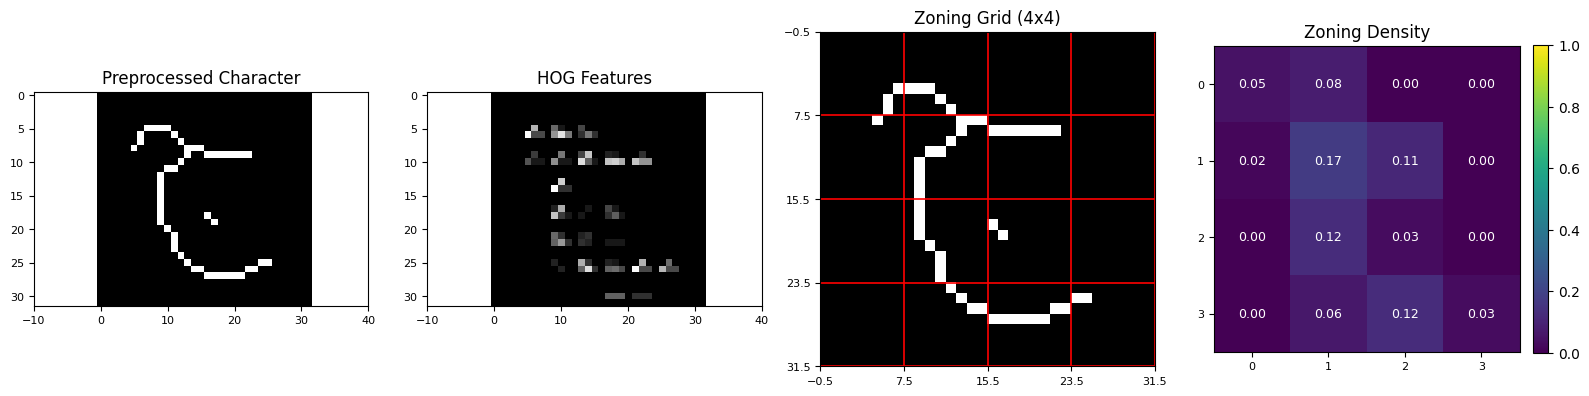

HOG features: 1764
Zoning features: 16
Combined features: 1780
Figure saved successfully!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import feature
import os

sample = preprocess_batch(
    X_train[:1],
    CONFIGS["main_full"]
)[0]

params = HOG_SETTINGS["hog_o9_p4"]

hog_vector, hog_image = feature.hog(
    sample,
    orientations=params["orientations"],
    pixels_per_cell=params["pixels_per_cell"],
    cells_per_block=params["cells_per_block"],
    block_norm="L2-Hys",
    visualize=True,
    feature_vector=True
)

zone_values = zoning_features(
    sample[np.newaxis, :, :], 4
)[0].reshape(4, 4)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(sample, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Preprocessed Character")

axes[1].imshow(hog_image, cmap="gray")
axes[1].set_title("HOG Features")

axes[2].imshow(sample, cmap="gray", vmin=0, vmax=255)
axes[2].set_xticks(np.arange(-0.5, 32, 8))
axes[2].set_yticks(np.arange(-0.5, 32, 8))
axes[2].grid(color="red", linewidth=1.2)
axes[2].set_title("Zoning Grid (4x4)")

im = axes[3].imshow(
    zone_values,
    cmap="viridis",
    vmin=0,
    vmax=1
)

axes[3].set_title("Zoning Density")
axes[3].set_xticks(range(4))
axes[3].set_yticks(range(4))

for r in range(4):
    for c in range(4):
        axes[3].text(
            c, r,
            f"{zone_values[r,c]:.2f}",
            ha="center",
            va="center",
            color="white",
            fontsize=9
        )

fig.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xticks(ax.get_xticks())
    ax.tick_params(labelsize=8)

plt.tight_layout()

os.makedirs(FIG_DIR, exist_ok=True)

fig.savefig(
    os.path.join(FIG_DIR, "joud_hog_zoning.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("HOG features:", len(hog_vector))
print("Zoning features:", len(zone_values.flatten()))
print("Combined features:", len(hog_vector) + len(zone_values.flatten()))
print("Figure saved successfully!")

## 7. SVM (owner: Retal)

Done (Retal):
- An RBF-kernel SVM is trained on the standardized HOG + zoning features.
- `C` and `gamma` were tuned on the **validation** set only, with the full pipeline (section 9.2), over C ∈ {1, 10, 100} and gamma ∈ {scale, 0.01, 0.001}.
- The best setting, C = 10 and gamma = 0.001 (86.71% validation accuracy), is stored in `BEST_SVM`.
- The same `C` and `gamma` are used in every ablation configuration, and the SVM is retrained from scratch for each one.


In [ ]:
SVM_GRID = {"C": [1, 10, 100], "gamma": ["scale", 0.01, 0.001]}
BEST_SVM = {"C": 10, "gamma": 0.001}  # Best hyperparameters selected using validation accuracy (Section 9.2).


def fit_svm(F_train, y_train, C, gamma):
    """Train an RBF-kernel SVM using standardized feature vectors."""
    clf = SVC(kernel="rbf", C=C, gamma=gamma, cache_size=1000)
    clf.fit(F_train, y_train)
    return clf


def tune_svm_on_full_pipeline(hog_name=None, grid=None):
    """Validation accuracy for every (C, gamma) in the grid, using the full pipeline (test data is never used)."""
    hog_params = HOG_SETTINGS[hog_name or DEFAULT_HOG]
    grid = grid or SVM_GRID
    flags = CONFIGS["main_full"]

    F_tr = extract_features(preprocess_batch(X_train, flags), hog_params)
    scaler = StandardScaler().fit(F_tr)
    F_tr = scaler.transform(F_tr)
    F_va = scaler.transform(extract_features(preprocess_batch(X_val, flags), hog_params))

    rows = []
    for C in grid["C"]:
        for gamma in grid["gamma"]:
            clf = fit_svm(F_tr, y_train, C=C, gamma=gamma)
            rows.append({
                "C": C,
                "gamma": gamma,
                "val_accuracy": accuracy_score(y_val, clf.predict(F_va))
            })

    return pd.DataFrame(rows).sort_values(
        "val_accuracy", ascending=False, kind="stable"
    ).reset_index(drop=True)


def _check_pred(y_pred, n, name):
    """Validate the shape and data type of predicted class labels."""
    y_pred = np.asarray(y_pred).astype(np.int64)
    assert y_pred.shape == (n,), (
        f"{name}: predictions must have shape ({n},), got {y_pred.shape}"
    )
    return y_pred


def run_svm_experiment(experiment_id, flags, hog_name=None, svm_params=None, evaluate_test=True, conditions=None):
    """Run one experiment: train a new SVM on a single preprocessing configuration and evaluate it.

    The configuration is applied to the training, validation and test data, and the scaler
    and the model are refitted from scratch. Validation results are always saved.
    evaluate_test=False is used for tuning runs (e.g. the HOG comparison): only the validation split is used.
    Returns (classifier, scaler, {condition: test predictions}).
    """
    hog_name = hog_name or DEFAULT_HOG
    hog_params = HOG_SETTINGS[hog_name]
    svm_params = svm_params or BEST_SVM
    prep_name = flags_to_string(flags)

    X_tr = preprocess_batch(X_train, flags)
    F_tr = extract_features(X_tr, hog_params)
    scaler = StandardScaler().fit(F_tr)  # Fit the scaler using training features only.
    clf = fit_svm(scaler.transform(F_tr), y_train, **svm_params)

    F_va = scaler.transform(
        extract_features(preprocess_batch(X_val, flags), hog_params)
    )
    y_va_pred = _check_pred(clf.predict(F_va), len(y_val), "val")
    save_result(
        experiment_id, "svm", prep_name, hog_name,
        "clean", "val", evaluate(y_val, y_va_pred)
    )

    preds = {}
    if evaluate_test:
        for cond in (conditions or CONDITIONS):
            X_te = X_test if cond == "clean" else DEGRADED[cond]
            F_te = scaler.transform(
                extract_features(preprocess_batch(X_te, flags), hog_params)
            )
            y_pred = _check_pred(clf.predict(F_te), len(y_test), cond)
            save_result(
                experiment_id, "svm", prep_name, hog_name,
                cond, "test", evaluate(y_test, y_pred)
            )
            preds[cond] = y_pred

    return clf, scaler, preds


IMPLEMENTED["svm (Retal)"] = True

## 8. CNN baseline (owner: Renad)

Small CNN: 3 conv blocks (32 -> 64 -> 128 filters, two 3x3 convolutions each, BatchNorm, ReLU, MaxPool, Dropout), one fully connected layer (256) and a 28-way output. Adam, batch size 128, up to 40 epochs, **early stopping on the validation loss** (patience 6, best epoch restored). The framework seed is fixed with `SEED` inside `fit_cnn()`.

Inputs come from `to_cnn_input()`: float32, shape `(N, 32, 32, 1)`, values in `[0, 1]`.
For the "with preprocessing" CNN, train **and** test it on preprocessed images (same config rule as the SVM).
`model.history` keeps the per-epoch loss/accuracy for the training-curve figure.

Run on a Colab GPU (Runtime > Change runtime type > GPU), then set `RUN_CNN = True` in section 1 and, after checking the results, `IMPLEMENTED["cnn (Renad)"] = True`.

In [ ]:
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F_torch

CNN_CONFIG = dict(
    channels=(32, 64, 128),     # three conv blocks
    hidden=256,                 # fully connected layer
    dropout_conv=0.25,
    dropout_fc=0.5,
    lr=1e-3,
    weight_decay=1e-4,
    batch_size=128,
    max_epochs=40,
    patience=6,                 # early stopping: epochs without validation-loss improvement
)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_torch_seed(seed=SEED):
    """Fix every random generator the CNN touches (python/numpy are fixed by set_seed)."""
    set_seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


class SmallCNN(nn.Module):
    """3 x [Conv3x3 -> BatchNorm -> ReLU -> Conv3x3 -> BatchNorm -> ReLU -> MaxPool -> Dropout] -> FC -> softmax logits."""

    def __init__(self, cfg=CNN_CONFIG):
        super().__init__()
        blocks, c_in = [], 1
        for c_out in cfg["channels"]:
            blocks += [nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
                       nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
                       nn.MaxPool2d(2), nn.Dropout(cfg["dropout_conv"])]
            c_in = c_out
        self.features = nn.Sequential(*blocks)
        side = IMG_SIZE // (2 ** len(cfg["channels"]))                 # 32 -> 4
        self.classifier = nn.Sequential(nn.Flatten(),
                                        nn.Linear(c_in * side * side, cfg["hidden"]), nn.ReLU(inplace=True),
                                        nn.Dropout(cfg["dropout_fc"]),
                                        nn.Linear(cfg["hidden"], N_CLASSES))

    def forward(self, x):
        return self.classifier(self.features(x))


def to_cnn_input(X):
    """uint8 (N, 32, 32) -> float32 (N, 32, 32, 1) scaled to [0, 1]."""
    assert_images(X, "to_cnn_input")
    return (X.astype(np.float32) / 255.0)[..., None]


def _to_tensor(X_cnn):
    """(N, 32, 32, 1) float32 numpy -> (N, 1, 32, 32) torch tensor."""
    return torch.from_numpy(np.ascontiguousarray(X_cnn.transpose(0, 3, 1, 2)))


def _eval_loss_acc(model, X_t, y_t, batch_size=512):
    model.eval()
    loss_sum, correct = 0.0, 0
    with torch.no_grad():
        for i in range(0, len(X_t), batch_size):
            xb, yb = X_t[i:i + batch_size].to(DEVICE), y_t[i:i + batch_size].to(DEVICE)
            out = model(xb)
            loss_sum += F_torch.cross_entropy(out, yb, reduction="sum").item()
            correct += (out.argmax(1) == yb).sum().item()
    return loss_sum / len(X_t), correct / len(X_t)


def fit_cnn(X_train_cnn, y_train, X_val_cnn, y_val, cfg=None):
    """Train a fresh CNN with early stopping on the VALIDATION loss and return the model (best epoch restored).

    The training history is stored in model.history (a dict of lists) for the training-curve figure.
    """
    cfg = cfg or CNN_CONFIG
    set_torch_seed(SEED)
    X_tr, y_tr = _to_tensor(X_train_cnn), torch.from_numpy(np.asarray(y_train, dtype=np.int64))
    X_va, y_va = _to_tensor(X_val_cnn), torch.from_numpy(np.asarray(y_val, dtype=np.int64))
    model = SmallCNN(cfg).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    gen = torch.Generator().manual_seed(SEED)                      # fixed shuffling order
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0
    for epoch in range(cfg["max_epochs"]):
        model.train()
        perm = torch.randperm(len(X_tr), generator=gen)
        for i in range(0, len(perm), cfg["batch_size"]):
            idx = perm[i:i + cfg["batch_size"]]
            xb, yb = X_tr[idx].to(DEVICE), y_tr[idx].to(DEVICE)
            opt.zero_grad()
            F_torch.cross_entropy(model(xb), yb).backward()
            opt.step()
        tr_loss, tr_acc = _eval_loss_acc(model, X_tr, y_tr)        # train metrics in eval mode (no dropout)
        va_loss, va_acc = _eval_loss_acc(model, X_va, y_va)
        for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
            history[k].append(v)
        if va_loss < best_loss - 1e-4:
            best_loss, best_epoch, wait = va_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= cfg["patience"]:
                break
    model.load_state_dict(best_state)
    model.history = history
    model.best_epoch = best_epoch
    print(f"  CNN trained {len(history['val_loss'])} epochs on {DEVICE}, best epoch {best_epoch + 1}, "
          f"val acc {history['val_acc'][best_epoch]:.4f}")
    return model


def predict_cnn(model, X_cnn, batch_size=512):
    """Integer class predictions, shape (N,)."""
    X_t = _to_tensor(X_cnn)
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(X_t), batch_size):
            preds.append(model(X_t[i:i + batch_size].to(DEVICE)).argmax(1).cpu().numpy())
    return np.concatenate(preds).astype(np.int64)


def cnn_architecture_table(cfg=CNN_CONFIG):
    """Layer-by-layer table for the paper (Section V-D)."""
    rows, c_in, side = [], 1, IMG_SIZE
    for i, c_out in enumerate(cfg["channels"], 1):
        rows.append({"layer": f"Block {i}", "operations": f"2 x [Conv3x3({c_in}->{c_out}) + BN + ReLU], MaxPool2x2, Dropout({cfg['dropout_conv']})",
                     "output": f"{c_out} x {side // 2} x {side // 2}"})
        c_in, side = c_out, side // 2
    rows.append({"layer": "Classifier", "operations": f"Flatten, FC({c_in * side * side}->{cfg['hidden']}) + ReLU, Dropout({cfg['dropout_fc']}), FC({cfg['hidden']}->{N_CLASSES})",
                 "output": str(N_CLASSES)})
    return pd.DataFrame(rows)


def plot_training_curves(model, title="CNN training curves", filename=None):
    """Loss and accuracy per epoch (train vs validation) with the early-stopping epoch marked."""
    h = model.history
    ep = np.arange(1, len(h["val_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
    for ax, key, label in [(axes[0], "loss", "Loss"), (axes[1], "acc", "Accuracy")]:
        ax.plot(ep, h[f"train_{key}"], label="train")
        ax.plot(ep, h[f"val_{key}"], label="validation")
        ax.axvline(model.best_epoch + 1, color="gray", linestyle="--", linewidth=0.8, label="best epoch")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(label)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    if filename:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, filename), dpi=150, bbox_inches="tight")
    return fig


def run_cnn_experiment(experiment_id, flags, conditions=None):
    """Same rules as run_svm_experiment: one preprocessing config for train and test, a freshly trained CNN."""
    prep_name = flags_to_string(flags)
    X_tr = to_cnn_input(preprocess_batch(X_train, flags))
    X_va = to_cnn_input(preprocess_batch(X_val, flags))
    model = fit_cnn(X_tr, y_train, X_va, y_val)

    y_va_pred = _check_pred(predict_cnn(model, X_va), len(y_val), "val")
    save_result(experiment_id, "cnn", prep_name, NO_HOG, "clean", "val", evaluate(y_val, y_va_pred))

    preds = {}
    for cond in (conditions or CONDITIONS):
        X_te = X_test if cond == "clean" else DEGRADED[cond]
        X_te = to_cnn_input(preprocess_batch(X_te, flags))
        y_pred = _check_pred(predict_cnn(model, X_te), len(y_test), cond)
        save_result(experiment_id, "cnn", prep_name, NO_HOG, cond, "test", evaluate(y_test, y_pred))
        preds[cond] = y_pred
    return model, preds


IMPLEMENTED["cnn (Renad)"] = True             # Renad: set True after the real-data run on Colab (see section 9.4)

## Self-test
Run `selftest()` after changing **any** function. It checks the shared contract on a small slice and does not touch `results.csv`.

In [ ]:
def selftest(n=64):
    Xs, ys = X_train[:n], y_train[:n]
    assert_images(Xs, "X slice")
    assert_labels(ys, len(Xs), "y slice")
    for name, flags in CONFIGS.items():
        Xp = preprocess_batch(Xs, flags)
        assert Xp.shape == Xs.shape and Xp.dtype == np.uint8, f"config {name}: bad output {Xp.shape} {Xp.dtype}"
    for hog_name, params in HOG_SETTINGS.items():
        F = extract_features(Xs, params)
        assert F.ndim == 2 and len(F) == len(Xs) and np.isfinite(F).all(), f"{hog_name}: bad features"
    for cond, arr in DEGRADED.items():
        assert_images(arr, f"degraded {cond}")
        assert arr.shape == X_test.shape, f"degraded {cond}: wrong shape"
    m = evaluate(ys, ys)
    assert set(m) == set(METRIC_COLUMNS) and m["accuracy"] == 1.0, "evaluate() contract broken"
    tmp = os.path.join(tempfile.gettempdir(), "arti403_selftest_results.csv")
    if os.path.exists(tmp):
        os.remove(tmp)
    save_result("selftest", "svm", "raw", DEFAULT_HOG, "clean", "val", m, path=tmp)
    save_result("selftest", "svm", "raw", DEFAULT_HOG, "clean", "val", m, path=tmp)   # same key: must not duplicate
    df = pd.read_csv(tmp, keep_default_na=False)
    os.remove(tmp)
    assert list(df.columns) == RESULT_COLUMNS and len(df) == 1, "save_result() contract broken"
    print("selftest OK")


selftest()

selftest OK


## 9. Experiments

Order matters: HOG comparison → choose `DEFAULT_HOG` → tune the SVM → fix `BEST_SVM` → ablation → CNN → tables.
Tuning runs touch the validation split only.

In [ ]:
if FINAL_RUN:
    reset_results()                       # the final Run All starts from an empty results file

### 9.1 HOG settings comparison (owner: Joud) — validation only

In [ ]:
for hog_name in HOG_SETTINGS:
    run_svm_experiment(hog_name, CONFIGS["main_full"], hog_name=hog_name, evaluate_test=False)

_res = load_results()
hog_table = (_res[(_res["split"] == "val") & (_res["model"] == "svm") & (_res["experiment_id"].isin(list(HOG_SETTINGS)))]
             .sort_values("accuracy", ascending=False, kind="stable").reset_index(drop=True))
show(hog_table)

,experiment_id,model,preprocessing,hog_settings,condition,split,accuracy,precision,recall,f1
0,hog_o9_p4,svm,center+median+otsu+thin,hog_o9_p4,clean,val,0.867063,0.869235,0.867063,0.866908
1,hog_o12_p4,svm,center+median+otsu+thin,hog_o12_p4,clean,val,0.867063,0.869235,0.867063,0.866908
2,hog_o9_p8,svm,center+median+otsu+thin,hog_o9_p8,clean,val,0.822421,0.826002,0.822421,0.822684
3,hog_o12_p8,svm,center+median+otsu+thin,hog_o12_p8,clean,val,0.822421,0.826002,0.822421,0.822684


#### 9.1.1 HOG orientation analysis (validation only)



In [ ]:

import numpy as np
from sklearn.preprocessing import StandardScaler

X_tr = preprocess_batch(X_train, CONFIGS["main_full"])
X_va = preprocess_batch(X_val, CONFIGS["main_full"])

for cell_size in [4, 8]:
    predictions = {}

    for orientations in [9, 12]:
        name = f"hog_o{orientations}_p{cell_size}"

        F_tr = extract_features(X_tr, HOG_SETTINGS[name])
        F_va = extract_features(X_va, HOG_SETTINGS[name])

        scaler = StandardScaler()
        F_tr_scaled = scaler.fit_transform(F_tr)
        F_va_scaled = scaler.transform(F_va)

        clf = fit_svm(F_tr_scaled, y_train, **BEST_SVM)
        predictions[name] = clf.predict(F_va_scaled)

    p9 = predictions[f"hog_o9_p{cell_size}"]
    p12 = predictions[f"hog_o12_p{cell_size}"]

    print(f"Cell size: {cell_size}x{cell_size}")
    print("Identical predictions:", np.array_equal(p9, p12))
    print("Different predictions:", np.sum(p9 != p12))
    print("-" * 40)


Cell size: 4x4
Identical predictions: True
Different predictions: 0
----------------------------------------
Cell size: 8x8
Identical predictions: True
Different predictions: 0
----------------------------------------


In [ ]:

import numpy as np

X_processed = preprocess_batch(X_val, CONFIGS["main_full"])

for n_bins in [9, 12]:
    total_hist = np.zeros(n_bins, dtype=float)

    for img in X_processed:
        img = np.asarray(img, dtype=float).squeeze()

        gy, gx = np.gradient(img)
        magnitude = np.hypot(gx, gy)
        angles = np.mod(
            np.degrees(np.arctan2(gy, gx)), 180
        )

        hist, _ = np.histogram(
            angles[magnitude > 1e-8],
            bins=n_bins,
            range=(0, 180),
            weights=magnitude[magnitude > 1e-8]
        )

        total_hist += hist

    print(f"\nOrientations: {n_bins}")
    print("Gradient energy:", np.round(total_hist, 2))
    print("Non-empty bins:", np.sum(total_hist > 1e-8))
    print("Empty bins:", np.sum(total_hist <= 1e-8))



Orientations: 9
Gradient energy: [ 8141130.          0.    5856721.52        0.   10194390.          0.
  4153852.82        0.          0.  ]
Non-empty bins: 4
Empty bins: 5

Orientations: 12
Gradient energy: [ 8141130.          0.          0.    5856721.52        0.          0.
 10194390.          0.          0.    4153852.82        0.          0.  ]
Non-empty bins: 4
Empty bins: 8


### 9.2 SVM tuning on the validation set (owner: Retal)

In [ ]:
svm_tuning_table = tune_svm_on_full_pipeline()
show(svm_tuning_table)

,C,gamma,val_accuracy
0,10,0.001,0.867063
1,100,scale,0.865079
2,100,0.001,0.864583
3,10,scale,0.864087
4,1,scale,0.845238
5,1,0.001,0.843254
6,10,0.01,0.535218
7,100,0.01,0.535218
8,1,0.01,0.515377


### 9.3a Ablation: six configs, SVM retrained for each (owners: Lina + Retal)

In [ ]:
svm_preds = {}

for exp_id, flags in CONFIGS.items():
    print("running", exp_id, "->", flags_to_string(flags))
    model, scaler, preds = run_svm_experiment(exp_id, flags)
    svm_preds[exp_id] = preds

running main_full -> center+median+otsu+thin
running abl_no_center -> median+otsu+thin
running abl_no_median -> center+otsu+thin
running abl_no_otsu -> center+median+thin
running abl_no_thin -> center+median+otsu
running abl_none -> raw


### 9.3b SVM Results and Error Analysis (owner: Retal)

Comparison of SVM performance with and without preprocessing across all test conditions, including accuracy, precision, recall, and F1-score. A confusion matrix for the clean test set and the most frequent misclassifications under clean and noisy conditions are also presented.

accuracy  precision  recall      f1
experiment_id condition                                      
main_full     clean         0.8682     0.8705  0.8682  0.8680
              noise_0.05    0.8661     0.8678  0.8661  0.8660
              noise_0.1     0.8461     0.8483  0.8461  0.8462
              blur_3        0.7158     0.7469  0.7158  0.7155
              blur_5        0.3729     0.4719  0.3729  0.3467
              rot_5         0.8524     0.8551  0.8524  0.8522
              rot_10        0.8312     0.8350  0.8312  0.8314
abl_none      clean         0.7485     0.8033  0.7485  0.7649
              noise_0.05    0.0357     0.0013  0.0357  0.0025
              noise_0.1     0.0357     0.0013  0.0357  0.0025
              blur_3        0.6143     0.7486  0.6143  0.6526
              blur_5        0.3476     0.5423  0.3476  0.3637
              rot_5         0.7265     0.7989  0.7265  0.7481
              rot_10        0.7158     0.7898  0.7158  0.7384

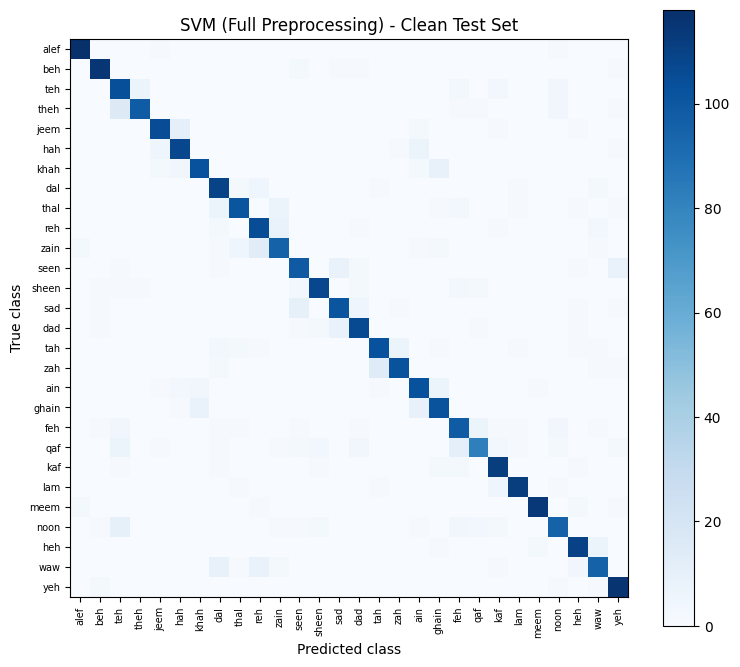

Most Frequent Misclassifications - Clean Test Set


,count,true,predicted
0,15,theh,teh
1,14,zah,tah
2,13,zain,reh
3,11,qaf,feh
4,11,jeem,hah
5,10,sad,seen
6,10,noon,teh
7,9,waw,dal


Most Frequent Misclassifications - Gaussian Noise (Sigma = 0.1)


,count,true,predicted
0,18,theh,teh
1,14,zah,tah
2,14,qaf,feh
3,12,zain,reh
4,12,waw,reh
5,10,khah,ghain
6,10,ghain,ain
7,10,dad,sad


In [ ]:
def most_confused_pairs(y_true, y_pred, k=8):
    """Return the k most frequent misclassification pairs, including their true and predicted class labels."""
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(N_CLASSES))
    np.fill_diagonal(cm, 0)

    pairs = sorted(
        (
            (cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j])
            for i in range(N_CLASSES)
            for j in range(N_CLASSES)
            if cm[i, j]
        ),
        reverse=True
    )[:k]

    return pd.DataFrame(pairs, columns=["count", "true", "predicted"])


r = load_results()
r = r[
    (r["model"] == "svm")
    & (r["split"] == "test")
    & (r["hog_settings"] == DEFAULT_HOG)
    & (r["experiment_id"].isin(["main_full", "abl_none"]))
]

svm_table = (
    r.pivot_table(
        index=["experiment_id", "condition"],
        values=METRIC_COLUMNS,
        aggfunc="first"
    )
    .reindex(columns=METRIC_COLUMNS)
    .reindex(
        pd.MultiIndex.from_product(
            [["main_full", "abl_none"], CONDITIONS],
            names=["experiment_id", "condition"]
        )
    )
    .round(4)
)

show(svm_table)


fig = plot_confusion_matrix(
    y_test,
    svm_preds["main_full"]["clean"],
    title="SVM (Full Preprocessing) - Clean Test Set"
)
ax = fig.axes[0]
ax.set_xticklabels(CLASS_NAMES, rotation=90)
ax.set_yticklabels(CLASS_NAMES)
os.makedirs(FIG_DIR, exist_ok=True)
fig.savefig(
    os.path.join(FIG_DIR, "fig_cm_svm_main_full_clean.png"),
    dpi=150,
    bbox_inches="tight"
)
plt.show()


print("Most Frequent Misclassifications - Clean Test Set")
show(most_confused_pairs(y_test, svm_preds["main_full"]["clean"]))

print("Most Frequent Misclassifications - Gaussian Noise (Sigma = 0.1)")
show(most_confused_pairs(y_test, svm_preds["main_full"]["noise_0.1"]))

### 9.3c Raw-image SVM under noise (owner: Retal)

Distribution of the predictions of the SVM trained on raw images (`abl_none`) on the clean and noisy test sets, to explain its accuracy drop to chance level (1/28 = 3.57%) under Gaussian noise.

In [ ]:
from collections import Counter

for cond in ["clean", "noise_0.05", "noise_0.1"]:
    y_pred = svm_preds["abl_none"][cond]
    counts = Counter(y_pred)

    print(f"Condition: {cond}")
    print(f"Accuracy: {np.mean(y_pred == y_test) * 100:.2f}%")
    print(f"Number of predicted classes: {len(counts)} / {N_CLASSES}")
    print("Top 5 predicted classes:")
    for class_id, count in counts.most_common(5):
        print(f"  {CLASS_NAMES[class_id]}: {count} images ({count / len(y_pred) * 100:.2f}%)")
    print("-" * 45)


Condition: clean
Accuracy: 74.85%
Number of predicted classes: 28 / 28
Top 5 predicted classes:
  ghain: 429 images (12.77%)
  sheen: 149 images (4.43%)
  yeh: 130 images (3.87%)
  dal: 121 images (3.60%)
  reh: 121 images (3.60%)
---------------------------------------------
Condition: noise_0.05
Accuracy: 3.57%
Number of predicted classes: 1 / 28
Top 5 predicted classes:
  ghain: 3360 images (100.00%)
---------------------------------------------
Condition: noise_0.1
Accuracy: 3.57%
Number of predicted classes: 1 / 28
Top 5 predicted classes:
  ghain: 3360 images (100.00%)
---------------------------------------------


### 9.4 CNN: with and without preprocessing (owner: Renad)

running CNN main_full
  CNN trained 24 epochs on cuda, best epoch 18, val acc 0.9256


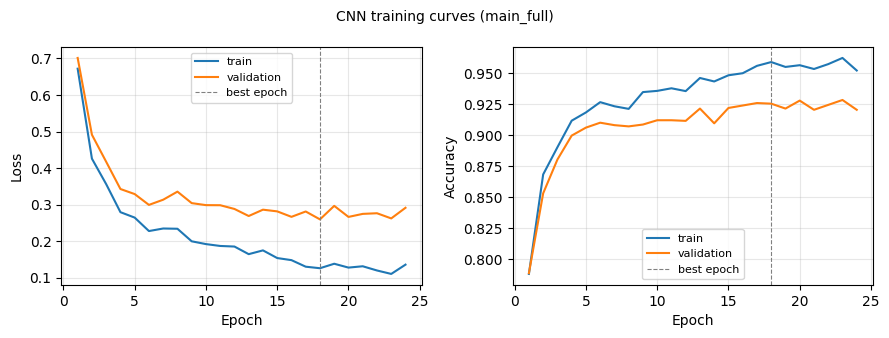

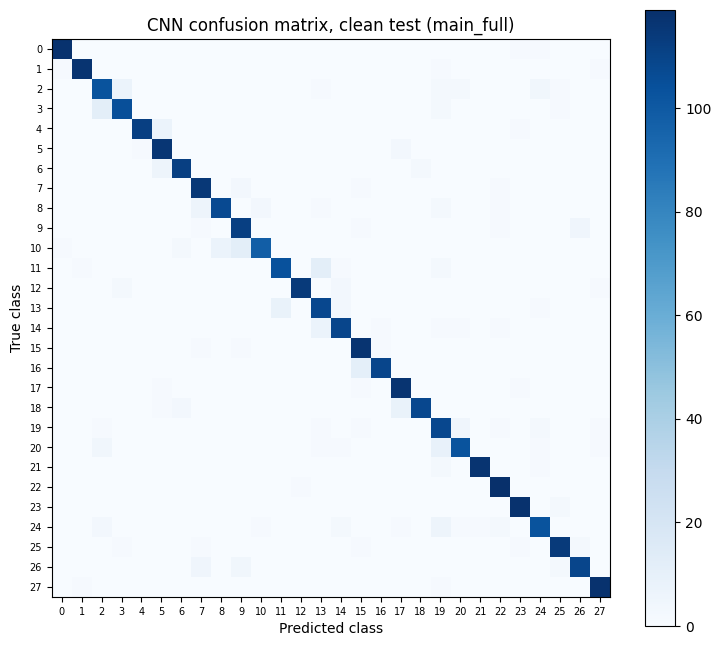

running CNN abl_none
  CNN trained 19 epochs on cuda, best epoch 13, val acc 0.9722


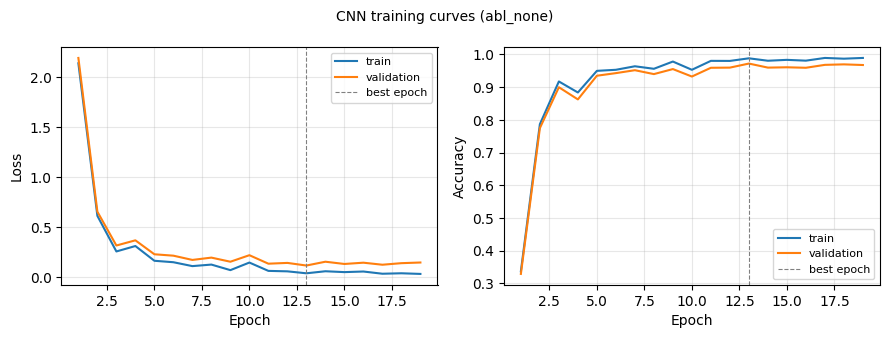

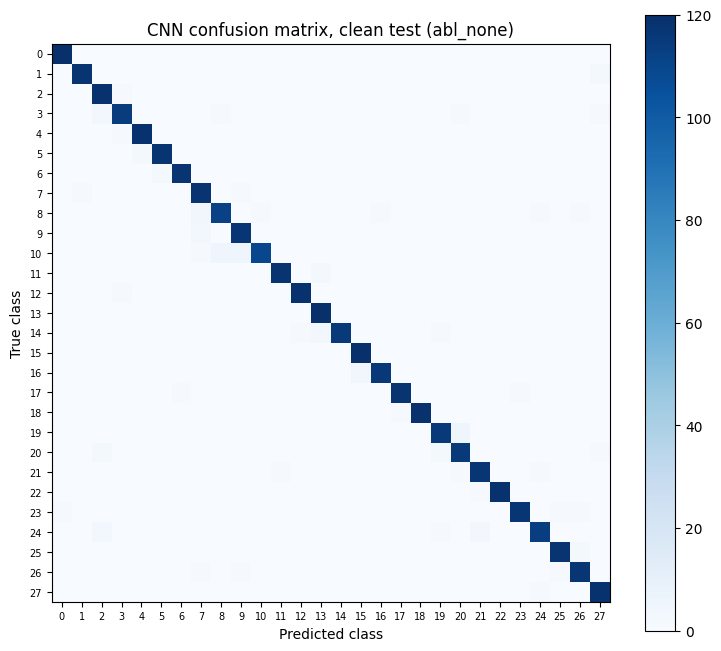

,layer,operations,output
0,Block 1,"2 x [Conv3x3(1->32) + BN + ReLU], MaxPool2x2, ...",32 x 16 x 16
1,Block 2,"2 x [Conv3x3(32->64) + BN + ReLU], MaxPool2x2,...",64 x 8 x 8
2,Block 3,"2 x [Conv3x3(64->128) + BN + ReLU], MaxPool2x2...",128 x 4 x 4
3,Classifier,"Flatten, FC(2048->256) + ReLU, Dropout(0.5), F...",28


In [ ]:
CNN_MODELS, CNN_PREDS = {}, {}
if RUN_CNN:
    for exp_id in ("main_full", "abl_none"):
        print("running CNN", exp_id)
        CNN_MODELS[exp_id], CNN_PREDS[exp_id] = run_cnn_experiment(exp_id, CONFIGS[exp_id])
        plot_training_curves(CNN_MODELS[exp_id], title=f"CNN training curves ({exp_id})",
                             filename=f"cnn_curves_{exp_id}.png")
        plt.show()
        plot_confusion_matrix(y_test, CNN_PREDS[exp_id]["clean"], title=f"CNN confusion matrix, clean test ({exp_id})",
                              filename=f"cnn_confusion_{exp_id}.png")
        plt.show()
    show(cnn_architecture_table())
else:
    print("RUN_CNN is False: the CNN experiments are skipped.")

## 10. Results tables (owner: Renad)

condition,clean,noise_0.05,noise_0.1,blur_3,blur_5,rot_5,rot_10
experiment_id,,,,,,,
main_full,0.868155,0.866071,0.846131,0.715774,0.372917,0.852381,0.831250
abl_no_center,0.655060,0.659524,0.640774,0.563690,0.387202,0.638095,0.630060
abl_no_median,0.877976,0.880655,0.853571,0.706548,0.353571,0.867560,0.837798
abl_no_otsu,0.845238,0.846726,0.830060,0.502381,0.084226,0.827381,0.797321
abl_no_thin,0.913988,0.911905,0.900595,0.828869,0.488393,0.904464,0.884524
abl_none,0.748512,0.035714,0.035714,0.614286,0.347619,0.726488,0.715774


condition                         clean  noise_0.05  noise_0.1    blur_3  \
model preprocessing                                                        
cnn   center+median+otsu+thin  0.925595    0.921131   0.916964  0.780655   
      raw                      0.975298    0.055060   0.038690  0.665774   
svm   center+median+otsu+thin  0.868155    0.866071   0.846131  0.715774   
      raw                      0.748512    0.035714   0.035714  0.614286   

condition                        blur_5     rot_5    rot_10  
model preprocessing                                          
cnn   center+median+otsu+thin  0.410714  0.917857  0.908036  
      raw                      0.238095  0.966667  0.964881  
svm   center+median+otsu+thin  0.372917  0.852381  0.831250  
      raw                      0.347619  0.726488  0.715774

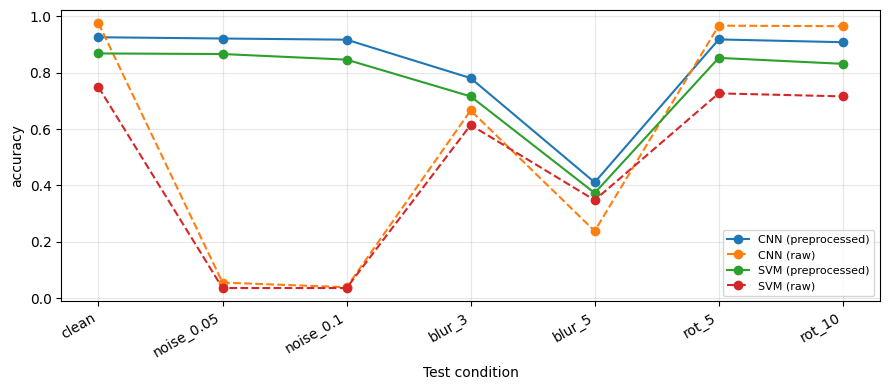

,model,baa/taa/thaa mix-ups,share of all errors,total errors
0,CNN (full),19,0.076,250
1,SVM (full),21,0.047,443
2,CNN (raw),4,0.048,83
3,SVM (raw),43,0.051,845


In [ ]:
def comparison_table(metric="accuracy"):
    """SVM vs CNN, with vs without preprocessing, for every test condition."""
    df = load_results()
    df = df[(df["split"] == "test") & (df["experiment_id"].isin(["main_full", "abl_none"]))]
    if df.empty:
        print("No test results yet.")
        return df
    t = df.pivot_table(index=["model", "preprocessing"], columns="condition", values=metric, aggfunc="first")
    return t.reindex(columns=[c for c in CONDITIONS if c in t.columns])


def ablation_table(metric="accuracy", model="svm"):
    """One row per ablation config, one column per test condition."""
    df = load_results()
    df = df[(df["split"] == "test") & (df["model"] == model) & (df["experiment_id"].isin(list(CONFIGS)))]
    if df.empty:
        print("No test results yet.")
        return df
    t = df.pivot_table(index="experiment_id", columns="condition", values=metric, aggfunc="first")
    return t.reindex(index=[c for c in CONFIGS if c in t.index], columns=[c for c in CONDITIONS if c in t.columns])


def robustness_figure(metric="accuracy", filename="robustness_svm_vs_cnn.png"):
    """Which model holds up better under noise / blur / rotation: one line per (model, preprocessing)."""
    t = comparison_table(metric)
    if t is None or len(t) == 0:
        return None
    fig, ax = plt.subplots(figsize=(9, 4))
    for (model_name, prep), row in t.iterrows():
        style = "-" if prep != "raw" else "--"
        ax.plot(range(len(row)), row.values, style, marker="o", label=f"{model_name.upper()} ({'raw' if prep == 'raw' else 'preprocessed'})")
    ax.set_xticks(range(len(t.columns)))
    ax.set_xticklabels(t.columns, rotation=30, ha="right")
    ax.set_ylabel(metric)
    ax.set_xlabel("Test condition")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()
    os.makedirs(FIG_DIR, exist_ok=True)
    fig.savefig(os.path.join(FIG_DIR, filename), dpi=150, bbox_inches="tight")
    return fig


# AHCD classes after the 1..28 -> 0..27 shift: 1 = baa, 2 = taa, 3 = thaa
BAA_TAA_THAA = (1, 2, 3)


def dotted_letters_confusion(y_true, y_pred, group=BAA_TAA_THAA):
    """3x3 confusion matrix restricted to the letters that differ only by their dots, plus the share of all errors they cause."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    cm = confusion_matrix(y_true, y_pred, labels=list(group))
    in_group_errors = int(cm.sum() - np.trace(cm))
    all_errors = int((y_true != y_pred).sum())
    share = in_group_errors / all_errors if all_errors else 0.0
    return pd.DataFrame(cm, index=[f"true {c}" for c in group], columns=[f"pred {c}" for c in group]), in_group_errors, share


def compare_dotted_errors(preds_by_model, condition="clean"):
    """preds_by_model = {'CNN (full)': y_pred, 'SVM (full)': y_pred, ...} on the same test condition."""
    rows = []
    for name, y_pred in preds_by_model.items():
        _, n_err, share = dotted_letters_confusion(y_test, y_pred)
        rows.append({"model": name, "baa/taa/thaa mix-ups": n_err, "share of all errors": round(share, 3),
                     "total errors": int((y_test != y_pred).sum())})
    return pd.DataFrame(rows)


show(ablation_table())
show(comparison_table())
fig = robustness_figure()
if fig is not None:
    plt.show()

# baa/taa/thaa errors (Section VI-F). SVM predictions come from svm_preds (section 9.3a).
_dotted = {}
for _eid, _label in (("main_full", "full"), ("abl_none", "raw")):
    if _eid in CNN_PREDS:
        _dotted[f"CNN ({_label})"] = CNN_PREDS[_eid]["clean"]
    if "svm_preds" in globals() and _eid in svm_preds:
        _dotted[f"SVM ({_label})"] = svm_preds[_eid]["clean"]
if _dotted:
    show(compare_dotted_errors(_dotted))

## 11. Final check (owner: Lina)
Before submitting: set `FINAL_RUN = True`, **Restart & Run All**

In [ ]:
ready = readiness_report()
if FINAL_RUN:
    assert not USE_SYNTHETIC, "FINAL_RUN is True but USE_SYNTHETIC is also True: the paper must use the real AHCD data."
    assert RUN_CNN, "FINAL_RUN is True but RUN_CNN is False: the CNN results are missing."
    assert ready, "FINAL_RUN is True but some parts are not marked as final (see the report above)."
    assert os.path.exists(RESULTS_PATH), "results.csv was not created"
    expected = len(CONFIGS) * len(CONDITIONS) + 2 * len(CONDITIONS)       # 6 SVM configs + 2 CNN runs, every condition
    n_test_rows = int((load_results()["split"] == "test").sum())
    assert n_test_rows == expected, f"expected {expected} test rows in results.csv, found {n_test_rows}"
    print("Final run OK")

[x] loader (Layan)
[x] center_resize (Layan)
[x] median (Maryam)
[x] degraded_sets (Maryam)
[x] evaluation (Maryam)
[x] otsu (Lina)
[x] thinning (Lina)
[x] preprocess_and_configs (Lina)
[x] features_hog_zoning (Joud)
[x] svm (Retal)
[x] cnn (Renad)
Final run OK


In [ ]:
# Colab only: download the figures and results.csv after the final Run All
!zip -r outputs.zip figures results.csv
from google.colab import files
files.download("outputs.zip")

  adding: figures/ (stored 0%)
  adding: figures/cnn_confusion_abl_none.png (deflated 20%)
  adding: figures/otsu_thinning_dots.png (deflated 29%)
  adding: figures/cnn_confusion_main_full.png (deflated 20%)
  adding: figures/fig_degraded_sets.png (deflated 24%)
  adding: figures/fig_class_distribution.png (deflated 20%)
  adding: figures/fig_sample_grid.png (deflated 29%)
  adding: figures/joud_hog_zoning.png (deflated 21%)
  adding: figures/fig_center_resize.png (deflated 33%)
  adding: figures/cnn_curves_abl_none.png (deflated 8%)
  adding: figures/robustness_svm_vs_cnn.png (deflated 5%)
  adding: figures/fig_cm_svm_main_full_clean.png (deflated 18%)
  adding: figures/fig_median_before_after.png (deflated 19%)
  adding: figures/cnn_curves_main_full.png (deflated 7%)
  adding: results.csv (deflated 75%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>